### Import Library & Memuat Data Hasil Model

In [7]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Memuat model terbaik dan hasil evaluasi dari folder output
best_model = joblib.load('../output/house_price_xgb_model.pkl')
hasil_xgb = joblib.load('../output/hasil_xgb.pkl')

y_test_actual = hasil_xgb['y_test']
y_pred_actual = hasil_xgb['y_pred_test']

print("Model dan hasil evaluasi berhasil dimuat!")

Model dan hasil evaluasi berhasil dimuat!


### Grafik Actual vs Predicted

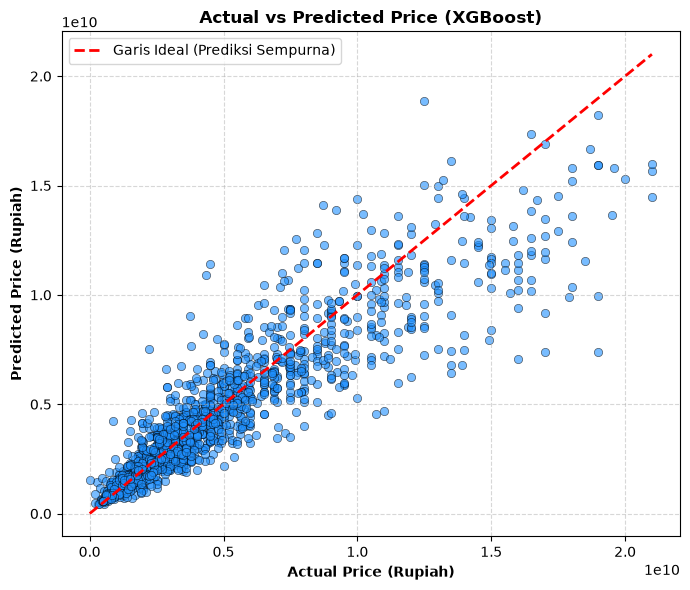

In [8]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test_actual, y_pred_actual, color='dodgerblue', alpha=0.6, edgecolors='k', linewidths=0.5)
plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()],
    'r--',
    linewidth=2,
    label='Garis Ideal (Prediksi Sempurna)'
)

plt.xlabel('Actual Price (Rupiah)', fontweight='bold')
plt.ylabel('Predicted Price (Rupiah)', fontweight='bold')
plt.title('Actual vs Predicted Price (XGBoost)', fontweight='bold', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Grafik Residual Plot

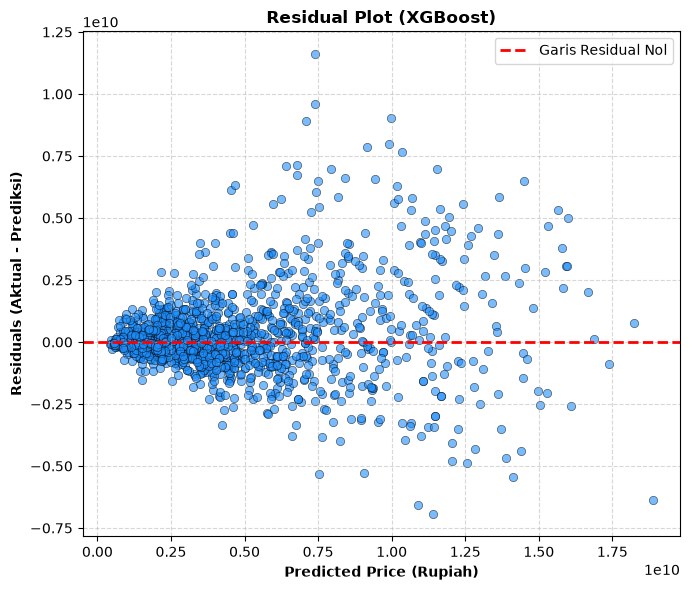

In [9]:
residuals = y_test_actual - y_pred_actual

plt.figure(figsize=(7, 6))

plt.scatter(y_pred_actual, residuals, color='dodgerblue', alpha=0.6, edgecolors='k', linewidths=0.5)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Garis Residual Nol')

plt.xlabel('Predicted Price (Rupiah)', fontweight='bold')
plt.ylabel('Residuals (Aktual - Prediksi)', fontweight='bold')
plt.title('Residual Plot (XGBoost)', fontweight='bold', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Grafik Feature Importance

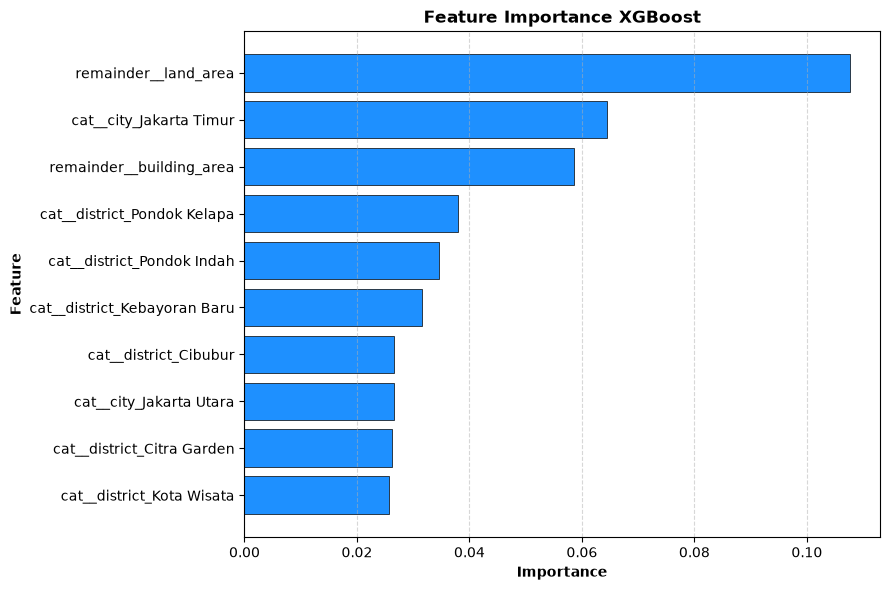

In [11]:
# Mengambil nama fitur setelah preprocessor dan bobot importance dari model XGBoost
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
importances = best_model.named_steps['xgb'].feature_importances_

# Membuat DataFrame untuk feature importance dan mengurutkan 10 teratas
df_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=True).tail(10)

plt.figure(figsize=(9, 6))
plt.barh(df_importance['feature'], df_importance['importance'], color='dodgerblue', edgecolor='k', linewidth=0.5)

plt.xlabel('Importance', fontweight='bold')
plt.ylabel('Feature', fontweight='bold')
plt.title('Feature Importance XGBoost', fontweight='bold', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()